This script demonstrates probability and risk analysis techniques.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import datetime as dt

from pathlib import Path
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

project_dir = Path.cwd()
data_dir = project_dir / 'Raw Data'
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import silhouette_score

# Get data

In [2]:
# Get the raw data here:  
# https://www.kaggle.com/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml/data?select=HI-Small_accounts.csv
    
# Load engineered AML dataset
# see 00. for CSV build
model_df = pd.read_csv(
    data_dir / 'aml_model_data.csv',
    parse_dates=['Timestamp']
)

# Sort chronologically.
model_df = model_df.sort_values('Timestamp').reset_index(drop=True)

print('Shape:', model_df.shape)
print('\nColumns:')
print(model_df.columns.tolist())

model_df.head()

Shape: (5077237, 20)

Columns:
['Timestamp', 'From Bank', 'Account', 'To Bank', 'Account.1', 'Amount Received', 'Receiving Currency', 'Amount Paid', 'Payment Currency', 'Payment Format', 'Is Laundering', 'transaction_date', 'amount_difference', 'amount_difference_pct', 'hour', 'day_of_week', 'is_weekend', 'amount_paid_log', 'amount_received_log', 'same_currency']


,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering,transaction_date,amount_difference,amount_difference_pct,hour,day_of_week,is_weekend,amount_paid_log,amount_received_log,same_currency
0,2022-09-01,32282,801B64CE0,32282,801B64CE0,29294.03,US Dollar,29294.03,US Dollar,Reinvestment,0,2022-09-01,0.0,0.0,0,3,0,10.285173,10.285173,1
1,2022-09-01,212818,804B1DF50,212818,804B1DF50,538528.53,Rupee,538528.53,Rupee,Reinvestment,0,2022-09-01,0.0,0.0,0,3,0,13.196598,13.196598,1
2,2022-09-01,16927,8062913A0,28,806291440,96718657.00,Ruble,96718657.00,Ruble,ACH,0,2022-09-01,0.0,0.0,0,3,0,18.387317,18.387317,1
3,2022-09-01,12561,802CF1BB0,18428,8095524B0,2122.85,Euro,2122.85,Euro,Credit Card,0,2022-09-01,0.0,0.0,0,3,0,7.660986,7.660986,1
4,2022-09-01,131086,80CB3F220,131086,80CB3F220,20289185.18,Mexican Peso,20289185.18,Mexican Peso,Reinvestment,0,2022-09-01,0.0,0.0,0,3,0,16.825599,16.825599,1


# Baseline probability

In [3]:
# Calculate class distribution.
class_distribution = model_df["Is Laundering"].value_counts().sort_index()

class_summary = pd.DataFrame({
    "Count": class_distribution,
    "Percentage": class_distribution / len(model_df) * 100
})

class_summary.index = ["Non-Laundering", "Laundering"]

# Store laundering probability as a decimal.
laundering_probability = (
    class_summary.loc["Laundering", "Percentage"] / 100
)

print(class_summary)
print("Laundering probability:", laundering_probability)

                  Count  Percentage
Non-Laundering  5072715   99.910936
Laundering         4522    0.089064
Laundering probability: 0.0008906418983395891


In [4]:
# calculate laundering odds

laundering_odds = laundering_probability / (1 - laundering_probability)

print(f"1 laundering transaction per {1 / laundering_probability:,.0f} transactions")
print(f"Laundering odds: 1:{1 / laundering_odds:,.0f}")

1 laundering transaction per 1,123 transactions
Laundering odds: 1:1,122


In [5]:
# calculate 95% Wilson confidence interval
# Wilson estimates the center and uncertainty of a proportion 
# while correcting for limitations of the simpler normal approximation.

from statsmodels.stats.proportion import proportion_confint

positive_count = model_df["Is Laundering"].sum()
total_count = len(model_df)

lower, upper = proportion_confint(
    positive_count,
    total_count,
    alpha=0.05,
    method="wilson"
)

print(f"Observed probability: {laundering_probability:.4%}")
print(f"95% confidence interval: [{lower:.4%}, {upper:.4%}]")

print("""
Sample proportion: 0.10% of transactions in model_df are labeled as laundering.

Confidence interval: A range of plausible values 
for the underlying population proportion from which those transactions could be viewed as a sample.
""")

Observed probability: 0.0891%
95% confidence interval: [0.0865%, 0.0917%]

Sample proportion: 0.10% of transactions in model_df are labeled as laundering.

Confidence interval: A range of plausible values 
for the underlying population proportion from which those transactions could be viewed as a sample.



# Conditional probability: 
P(Laundering|Payment Method)

In [6]:
# Calculate laundering probability within each payment format.
conditional_probability = (
    model_df.groupby("Payment Format")["Is Laundering"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "transaction_count",
        "sum": "laundering_count",
        "mean": "laundering_probability"
    })
)

# Convert probability to percentage.
conditional_probability["laundering_rate_pct"] = (
    conditional_probability["laundering_probability"] * 100
)

# Sort by laundering rate, highest first.
conditional_probability = conditional_probability.sort_values(
    "laundering_probability",
    ascending=False
)

display(conditional_probability.style.format({
    "transaction_count": "{:,.0f}",
    "laundering_count": "{:,.0f}",
    "laundering_probability": "{:.4f}",
    "laundering_rate_pct": "{:.3f}%"
}))

,transaction_count,laundering_count,laundering_probability,laundering_rate_pct
Payment Format,,,,
ACH,"599,689","3,828",0.0064,0.638%
Bitcoin,"146,091",56,0.0004,0.038%
Cash,"490,891",108,0.0002,0.022%
Cheque,"1,864,331",324,0.0002,0.017%
Credit Card,"1,323,324",206,0.0002,0.016%
Reinvestment,"481,056",0,0.0000,0.000%
Wire,"171,855",0,0.0000,0.000%


# Bayes theorem
## vs conditional probability

P(Laundering|Payment Method)  
An example using Bayes theorem to arrive at the same answer as conditional probability above.

Bayes' theorem is a method for calculating the probability of an event given some evidence when you know the probability in the reverse direction.

In [7]:
# Calculate the overall probability of laundering.
p_laundering = model_df["Is Laundering"].mean()

# Calculate the probability of each payment format.
p_format = (
    model_df["Payment Format"]
    .value_counts(normalize=True)
)

# Calculate P(Format | Laundering).
p_format_given_laundering = (
    model_df[model_df["Is Laundering"] == 1]
    ["Payment Format"]
    .value_counts(normalize=True)
)

# Apply Bayes' theorem to calculate P(Laundering | Format).
bayes_probability = (
    p_format_given_laundering * p_laundering
) / p_format

# Compare direct conditional probability with Bayes.
comparison = pd.DataFrame({
    "Direct Probability": conditional_probability[
        "laundering_probability"
    ],
    "Bayes Probability": bayes_probability
})

comparison["Difference"] = (
    comparison["Direct Probability"] -
    comparison["Bayes Probability"]
)

display(comparison.style.format("{:.6f}"))

,Direct Probability,Bayes Probability,Difference
ACH,0.006383,0.006383,0.000000
Bitcoin,0.000383,0.000383,0.000000
Cash,0.000220,0.000220,0.000000
Cheque,0.000174,0.000174,0.000000
Credit Card,0.000156,0.000156,0.000000
Reinvestment,0.000000,nan,nan
Wire,0.000000,nan,nan


## Bayes Theorem: New question: If a transaction uses ACH, how likely is it to be laundering?
P(Laundering|Payment Method=ACH)

In [8]:
# Define the transaction characteristic.
payment_method = "ACH"

# Overall laundering probability (prior).
p_laundering = model_df["Is Laundering"].mean()

# Probability of ACH among laundering transactions.
p_ach_given_laundering = (
    model_df.loc[model_df["Is Laundering"] == 1, "Payment Format"]
    .eq(payment_method).mean()
)

# Probability of ACH among non-laundering transactions.
p_ach_given_not_laundering = (
    model_df.loc[model_df["Is Laundering"] == 0, "Payment Format"]
    .eq(payment_method).mean()
)

# Overall probability of ACH.
p_ach = model_df["Payment Format"].eq(payment_method).mean()

# Bayes: probability of laundering given ACH.
p_laundering_given_ach = (
    p_ach_given_laundering * p_laundering
) / p_ach

# Direct conditional probability for validation.
p_direct = (
    model_df.loc[
        model_df["Payment Format"] == payment_method,
        "Is Laundering"
    ].mean()
)

# Compare ACH risk with the overall baseline.
risk_lift = p_laundering_given_ach / p_laundering

print("""
- Baseline laundering rate: Overall probability that a transaction is laundering.
- ACH transaction rate: Proportion of all transactions that use ACH.
- ACH rate among laundering: Proportion of laundering transactions that use ACH 
    (how prevelant ACH is among laundering).
- Laundering probability given ACH: Probability that an ACH transaction is laundering
    (how risky ACH is for laundering).
- Risk lift vs. baseline: How much higher or lower ACH laundering risk is compared with the overall baseline.
- Direct calculation: The conditional probability calculated directly from observed transaction labels, used to validate Bayes' result.
""")

print("Baseline laundering rate: {:.4%}".format(p_laundering))
print("ACH transaction rate: {:.4%}".format(p_ach))
print("ACH rate among laundering: {:.4%}".format(p_ach_given_laundering))
print("Laundering probability given ACH: {:.4%}".format(p_laundering_given_ach))
print("Risk lift vs. baseline: {:.2f}x".format(risk_lift))
print("Direct calculation: {:.4%}".format(p_direct))


- Baseline laundering rate: Overall probability that a transaction is laundering.
- ACH transaction rate: Proportion of all transactions that use ACH.
- ACH rate among laundering: Proportion of laundering transactions that use ACH 
    (how prevelant ACH is among laundering).
- Laundering probability given ACH: Probability that an ACH transaction is laundering
    (how risky ACH is for laundering).
- Risk lift vs. baseline: How much higher or lower ACH laundering risk is compared with the overall baseline.
- Direct calculation: The conditional probability calculated directly from observed transaction labels, used to validate Bayes' result.

Baseline laundering rate: 0.0891%
ACH transaction rate: 11.8113%
ACH rate among laundering: 84.6528%
Laundering probability given ACH: 0.6383%
Risk lift vs. baseline: 7.17x
Direct calculation: 0.6383%


In [9]:
print("""
Bayes theorem conclusion:
ACH risk is over 7 times that of the baseline.

Next steps
1. Compare all payment formats: 
Calculate laundering probability and risk lift for each format to identify 
which are most strongly associated with laundering.

2. Examine other transaction characteristics: 
Repeat the analysis by currency, transaction amount range, 
and time of day to identify additional risk indicators.

3. Combine indicators: 
Examine whether combinations of characteristics, 
such as ACH plus a particular currency, are associated with higher laundering probabilities.
""")


Bayes theorem conclusion:
ACH risk is over 7 times that of the baseline.

Next steps
1. Compare all payment formats: 
Calculate laundering probability and risk lift for each format to identify 
which are most strongly associated with laundering.

2. Examine other transaction characteristics: 
Repeat the analysis by currency, transaction amount range, 
and time of day to identify additional risk indicators.

3. Combine indicators: 
Examine whether combinations of characteristics, 
such as ACH plus a particular currency, are associated with higher laundering probabilities.



### Risk lift deep-dive

,transaction_count,laundering_count,laundering_probability,share_of_laundering,risk_lift
Payment Format,,,,,
ACH,"599,689","3,828",0.6383%,84.65%,7.17x
Bitcoin,"146,091",56,0.0383%,1.24%,0.43x
Cash,"490,891",108,0.0220%,2.39%,0.25x
Cheque,"1,864,331",324,0.0174%,7.16%,0.20x
Credit Card,"1,323,324",206,0.0156%,4.56%,0.17x
Reinvestment,"481,056",0,0.0000%,0.00%,0.00x
Wire,"171,855",0,0.0000%,0.00%,0.00x


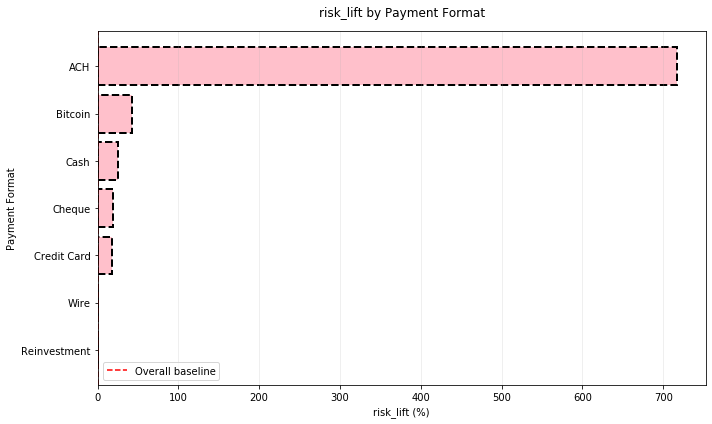

In [11]:
# Calculate baseline laundering probability.
baseline_rate = model_df["Is Laundering"].mean()

# Calculate conditional laundering probability by payment format.
payment_risk = (
    model_df.groupby("Payment Format")["Is Laundering"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "transaction_count",
        "sum": "laundering_count",
        "mean": "laundering_probability"
    })
)

# Calculate each format's share of all laundering transactions.
payment_risk["share_of_laundering"] = (
    payment_risk["laundering_count"] /
    model_df["Is Laundering"].sum()
)

# Compare each format's laundering rate with the baseline.
payment_risk["risk_lift"] = (
    payment_risk["laundering_probability"] / baseline_rate
)

# Sort by highest laundering probability.
payment_risk = payment_risk.sort_values(
    "laundering_probability",
    ascending=False
)

display(payment_risk.style.format({
    "transaction_count": "{:,.0f}",
    "laundering_count": "{:,.0f}",
    "laundering_probability": "{:.4%}",
    "share_of_laundering": "{:.2%}",
    "risk_lift": "{:.2f}x"
}))

# Plot laundering probability by payment format.
fig, ax = plt.subplots(figsize=(10, 6))

plot_data = payment_risk.sort_values(
    "risk_lift",
    ascending=True
)

ax.barh(
    plot_data.index,
    plot_data["risk_lift"] * 100,
    color="pink",
    edgecolor='black',
    lw=2,
    ls='--'
)

# Add overall baseline reference line.
ax.axvline(
    baseline_rate * 100,
    linestyle="--",
    color="red",
    linewidth=1.5,
    label="Overall baseline"
)

ax.set_title("risk_lift by Payment Format", pad=15)
ax.set_xlabel("risk_lift (%)")
ax.set_ylabel("Payment Format")
ax.legend()
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

In [12]:
print("""
Something is definitely going on with ACH...
""")


Something is definitely going on with ACH...



# Severity / impact

In [13]:
# summarize transaction severity by classification
severity = model_df.groupby("Is Laundering")["Amount Paid"].agg(
    ["count", "mean", "median", "std", "min", "max", "sum"]
)

severity.index = ["Non-Laundering", "Laundering"]

display(
    severity.style.format("{:,.2f}")
)

,count,mean,median,std,min,max,sum
Non-Laundering,"5,072,715.00","4,477,066.79","1,410.61","868,884,982.39",0.00,"1,046,302,363,293.48","22,710,883,842,344.62"
Laundering,"4,522.00","41,010,906.54","7,707.64","1,634,743,333.24",0.00,"84,853,144,179.58","185,451,319,367.94"


/opt/anaconda3/lib/python3.7/site-packages/matplotlib/cbook/__init__.py:1420: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  X = np.atleast_1d(X.T if isinstance(X, np.ndarray) else np.asarray(X))


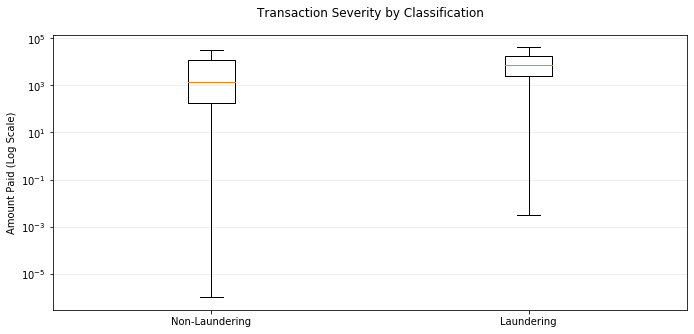

In [14]:
# compare transaction amount distributions
fig, ax = plt.subplots(figsize=(10, 5))

data = [
    model_df.loc[model_df["Is Laundering"] == 0, "Amount Paid"],
    model_df.loc[model_df["Is Laundering"] == 1, "Amount Paid"]
]

ax.boxplot(
    data,
    labels=["Non-Laundering", "Laundering"],
    showfliers=False
)

ax.set_yscale("log")
ax.set_title("Transaction Severity by Classification", pad=18)
ax.set_ylabel("Amount Paid (Log Scale)")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout(pad=2)
plt.show()

## By currency

In [15]:
# Estimate laundering probability by payment currency.
currency_summary = (
    model_df.groupby("Payment Currency")["Is Laundering"]
    .agg(["size", "sum", "mean"])
    .rename(columns={
        "size": "transaction_count",
        "sum": "laundering_count",
        "mean": "laundering_probability" # the mean of a Bernoulli variable is its probability of success.
    })
)

# Calculate average transaction severity among laundering-labeled transactions.
average_severity = (
    model_df[model_df["Is Laundering"] == 1]
    .groupby("Payment Currency")["Amount Paid"]
    .mean()
    .rename("average_severity")
)

currency_summary = currency_summary.join(average_severity)

# Probability-weighted transaction exposure.
currency_summary["expected_exposure_per_transaction"] = (
    currency_summary["laundering_probability"]
    * currency_summary["average_severity"]
)

display(currency_summary.style.format({
    "transaction_count": "{:,.0f}",
    "laundering_count": "{:,.0f}",
    "laundering_probability": "{:.4%}",
    "average_severity": "{:,.2f}",
    "expected_exposure_per_transaction": "{:,.2f}"
}))

,transaction_count,laundering_count,laundering_probability,average_severity,expected_exposure_per_transaction
Payment Currency,,,,,
Australian Dollar,"136,740",110,0.0804%,"1,631,039.10","1,312.08"
Bitcoin,"146,065",56,0.0383%,0.63,0.00
Brazil Real,"70,687",49,0.0693%,"41,642.05",28.87
Canadian Dollar,"140,020",116,0.0828%,"196,781,568.62","163,024.30"
Euro,"1,168,024","1,211",0.1037%,"1,012,001.70","1,049.24"
Mexican Peso,"110,128",78,0.0708%,"3,127,994.35","2,215.45"
Ruble,"155,150",119,0.0767%,"713,752,397.78","547,447.86"
Rupee,"190,161",148,0.0778%,"459,682,862.60","357,765.60"
Saudi Riyal,"88,934",302,0.3396%,"9,543,655.30","32,408.12"


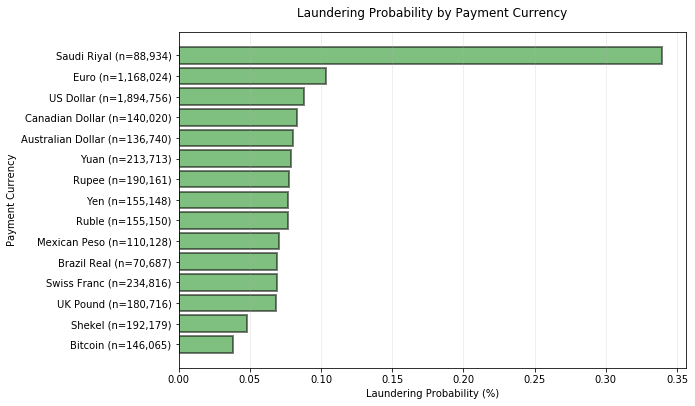

In [16]:
# Rank currencies by laundering probability.
plot_df = currency_summary.sort_values(
    "laundering_probability", ascending=True
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    plot_df.index,
    plot_df["laundering_probability"] * 100,
    edgecolor='black',
    lw=2,
    color='green',
    alpha=0.5
)

ax.set_title("Laundering Probability by Payment Currency", pad=15)
ax.set_xlabel("Laundering Probability (%)")
ax.set_ylabel("Payment Currency")
ax.grid(axis="x", alpha=0.25)

# Show transaction counts alongside currency labels.
labels = [
    "{} (n={:,.0f})".format(currency, count)
    for currency, count in zip(
        plot_df.index, plot_df["transaction_count"]
    )
]
ax.set_yticklabels(labels)

plt.tight_layout(pad=2)
plt.show()

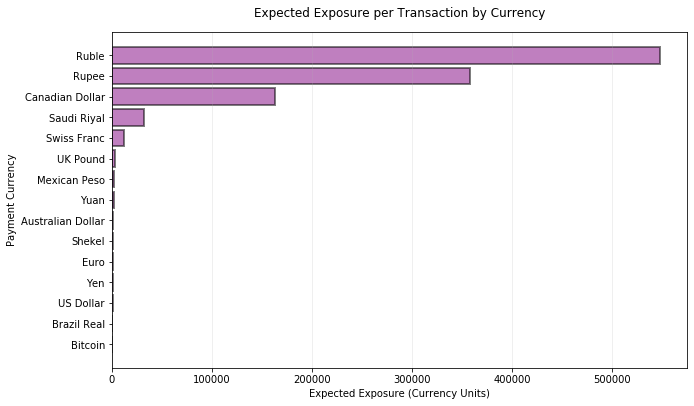

In [17]:
plot_df = currency_summary.sort_values(
    "expected_exposure_per_transaction", ascending=True
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    plot_df.index,
    plot_df["expected_exposure_per_transaction"],
    edgecolor='black',
    lw=2,
    color='purple',
    alpha=0.5
)

ax.set_title("Expected Exposure per Transaction by Currency", pad=15)
ax.set_xlabel("Expected Exposure (Currency Units)")
ax.set_ylabel("Payment Currency")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout(pad=2)
plt.show()

In [18]:
print("""
This is interesting.
The Saudi Riyal dominates in laundering probability, but it's 4th in terms of financial exposure.
Let's keep digging...
""")


This is interesting.
The Saudi Riyal dominates in laundering probability, but it's 4th in terms of financial exposure.
Let's keep digging...



### Saudi Riyal deep-dive

In [19]:
# Compare SAR with all other currencies.
sar = model_df[model_df["Payment Currency"] == "Saudi Riyal"]
other = model_df[model_df["Payment Currency"] != "Saudi Riyal"]

comparison = pd.DataFrame({
    "Transaction Count": [len(sar), len(other)],
    "Laundering Count": [
        sar["Is Laundering"].sum(),
        other["Is Laundering"].sum()
    ],
    "Laundering Rate": [
        sar["Is Laundering"].mean(),
        other["Is Laundering"].mean()
    ]
}, index=["SAR", "Other Currencies"])

display(comparison.style.format({
    "Transaction Count": "{:,.0f}",
    "Laundering Count": "{:,.0f}",
    "Laundering Rate": "{:.4%}"
}))

,Transaction Count,Laundering Count,Laundering Rate
SAR,"88,934",302,0.3396%
Other Currencies,"4,988,303","4,220",0.0846%


### Hypothesis test
Do SAR-denominated laundering transactions have a greater average USD transaction value than non-SAR laundering transactions?

In [20]:
# Group 1: SAR-denominated laundering transactions.
# Group 2: Non-SAR-denominated laundering transactions.
# Target: Average transaction value in USD.

# Null hypothesis (H0):
# The population mean USD transaction value for SAR laundering
# transactions is less than or equal to that of non-SAR transactions.

# Alternative hypothesis (H1):
# The population mean USD transaction value for SAR laundering
# transactions is greater than that of non-SAR transactions.

# Significance level: 0.05 (95% confidence).

# Statistical test: One-sided Welch's independent two-sample t-test.
# - Compares the means of two independent groups.
# - Does not assume equal population variances.
# - Accommodates unequal sample sizes.

# Decision rule:
# If p-value < 0.05, reject the null hypothesis.
# Otherwise, fail to reject the null hypothesis.

# Interpretation:
# A statistically significant result provides evidence that
# SAR laundering transactions have a greater population mean
# USD transaction value.

# Assumptions and limitations:
# - Transaction observations should be independent.
# - Transaction amounts may be highly skewed.
# - Multiple transactions from the same accounts may introduce dependence.
# - Supplement with a bootstrap confidence interval to assess robustness.

In [21]:
import requests
import pandas as pd
import numpy as np

# Keep only laundering transactions.
laundering_df = model_df[
    model_df["Is Laundering"] == 1
].copy()

currency_map = {
    "Australian Dollar": "AUD",
    "Bitcoin": "BTC",
    "Brazil Real": "BRL",
    "Canadian Dollar": "CAD",
    "Euro": "EUR",
    "Mexican Peso": "MXN",
    "Ruble": "RUB",
    "Rupee": "INR",
    "Saudi Riyal": "SAR",
    "Shekel": "ILS",
    "Swiss Franc": "CHF",
    "UK Pound": "GBP",
    "US Dollar": "USD",
    "Yen": "JPY",
    "Yuan": "CNY"
}

laundering_df["currency_code"] = (
    laundering_df["Payment Currency"].map(currency_map)
)

print(laundering_df[
    ["Payment Currency", "currency_code"]
].drop_duplicates())

         Payment Currency currency_code
11168           US Dollar           USD
43421                Yuan           CNY
48484         Saudi Riyal           SAR
68413     Canadian Dollar           CAD
69065                Euro           EUR
99236                 Yen           JPY
218713        Swiss Franc           CHF
332867  Australian Dollar           AUD
342889       Mexican Peso           MXN
368899              Ruble           RUB
406912           UK Pound           GBP
415460              Rupee           INR
495334        Brazil Real           BRL
514429             Shekel           ILS
615235            Bitcoin           BTC


In [22]:
# should be empty
print(
    laundering_df.loc[
        laundering_df["currency_code"].isna(),
        "Payment Currency"
    ].unique()
)

[]


In [23]:
# currencies to USD
laundering_df["transaction_date"] = pd.to_datetime(
    laundering_df["Timestamp"]
).dt.strftime("%Y-%m-%d")

# Identify currencies and date range.
currencies = laundering_df["Payment Currency"].unique()

start_date = laundering_df["transaction_date"].min()
end_date = laundering_df["transaction_date"].max()

currencies = laundering_df["currency_code"].dropna().unique()

fx_data = []

for currency in currencies:
    if currency == "USD":
        continue

    url = "https://api.frankfurter.dev/v2/rates"

    params = {
        "base": currency,
        "quotes": "USD",
        "from": start_date,
        "to": end_date
    }

    response = requests.get(url, params=params)
    response.raise_for_status()

    rates = pd.DataFrame(response.json())
    fx_data.append(rates)

fx_rates = pd.concat(fx_data, ignore_index=True)

print(fx_rates.head())

         date base quote     rate
0  2022-09-01  CNY   USD  0.14492
1  2022-09-02  CNY   USD  0.14483
2  2022-09-03  CNY   USD  0.14483
3  2022-09-04  CNY   USD  0.14482
4  2022-09-05  CNY   USD  0.14443


In [24]:
# Prepare exchange-rate table.
fx_rates = fx_rates.rename(columns={
    "date": "transaction_date",
    "base": "currency_code",
    "rate": "usd_rate"
})


# Ensure both date columns use the same format.
laundering_df["transaction_date"] = pd.to_datetime(
    laundering_df["transaction_date"]
).dt.strftime("%Y-%m-%d")

fx_rates["transaction_date"] = pd.to_datetime(
    fx_rates["transaction_date"]
).dt.strftime("%Y-%m-%d")

# Merge using ISO currency codes.
laundering_df = laundering_df.merge(
    fx_rates[["transaction_date", "currency_code", "usd_rate"]],
    on=["transaction_date", "currency_code"],
    how="left"
)

# USD transactions have an exchange rate of 1.
for str_ in ['USD','US Dollar','Bitcoin']:
    laundering_df.loc[
        laundering_df["Payment Currency"] == str_, "usd_rate"
    ] = 1.0

# Convert amounts.
laundering_df["amount_paid_usd"] = (
    laundering_df["Amount Paid"] * laundering_df["usd_rate"]
)

print("Missing exchange rates:", laundering_df["usd_rate"].isna().sum())

Missing exchange rates: 0


In [25]:
# Separate laundering transactions by payment currency.
sar_amounts = laundering_df.loc[
    laundering_df["currency_code"] == "SAR",
    "amount_paid_usd"
].dropna()

other_amounts = laundering_df.loc[
    laundering_df["currency_code"] != "SAR",
    "amount_paid_usd"
].dropna()

# Compare transaction severity.
comparison = pd.DataFrame({
    "SAR": sar_amounts.describe(),
    "Non-SAR": other_amounts.describe()
})

display(comparison)

# Calculate the difference in mean transaction value.
mean_difference = sar_amounts.mean() - other_amounts.mean()

print(f"SAR mean: ${sar_amounts.mean():,.2f}")
print(f"Non-SAR mean: ${other_amounts.mean():,.2f}")
print(f"Mean difference: ${mean_difference:,.2f}")

,SAR,Non-SAR
count,3.020000e+02,4.220000e+03
mean,2.545007e+06,6.066596e+06
std,3.991199e+07,2.568967e+08
min,1.013079e+01,3.227000e-03
25%,3.387564e+03,1.666086e+03
50%,7.961656e+03,4.693411e+03
75%,1.374339e+04,1.225740e+04
max,6.925858e+08,1.637020e+10


SAR mean: $2,545,006.56
Non-SAR mean: $6,066,595.57
Mean difference: $-3,521,589.02


In [26]:
from scipy.stats import ttest_ind
import numpy as np

# Exclude Bitcoin until a valid historical BTC/USD rate is available.
test_df = laundering_df[
    (laundering_df["currency_code"] != "BTC") &
    (laundering_df["usd_rate"].notna()) &
    (np.isfinite(laundering_df["amount_paid_usd"]))
].copy()

# Separate SAR and non-SAR transaction values.
sar_amounts = test_df.loc[
    test_df["currency_code"] == "SAR",
    "amount_paid_usd"
]

other_amounts = test_df.loc[
    test_df["currency_code"] != "SAR",
    "amount_paid_usd"
]

# Welch's one-sided independent two-sample t-test.
t_stat, p_value = ttest_ind(
    sar_amounts,
    other_amounts,
    equal_var=False,
    alternative="greater"
)

print(f"SAR sample size: {len(sar_amounts):,}")
print(f"Non-SAR sample size: {len(other_amounts):,}")
print(f"t-statistic: {t_stat:.4f}")
print(f"p-value: {p_value:.6f}")

# Statistical decision at alpha = 0.05.
if p_value < 0.05:
    print("Reject H0: Evidence supports higher mean SAR transaction severity.")
else:
    print("Fail to reject H0: Insufficient evidence of higher mean SAR severity.")

SAR sample size: 302
Non-SAR sample size: 4,164
t-statistic: -0.7800
p-value: 0.782286
Fail to reject H0: Insufficient evidence of higher mean SAR severity.


In [27]:
print("""
Interesting...
Even though the SAR has the highest laundering probability, 
It's avg financial impact is no greater than the avg of all other currencies.

Next step would be understand what's causing the high laundering probability.
Perhaps this goes the other way; low laundering probabilities are linked to high financial impact.
""")


Interesting...
Even though the SAR has the highest laundering probability, 
It's avg financial impact is no greater than the avg of all other currencies.

Next step would be understand what's causing the high laundering probability.
Perhaps this goes the other way; low laundering probabilities are linked to high financial impact.



# Institutional risk tolerance simulation

In [28]:
# Calculate daily laundering rates.
daily_risk = (
    model_df.set_index("Timestamp")["Is Laundering"]
    .resample("D")
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "transaction_count",
        "sum": "laundering_count",
        "mean": "laundering_rate"
    })
)

# Define hypothetical institutional risk thresholds.
risk_appetite = 0.0010        # Target: 0.10%
warning_threshold = 0.0015   # Warning: 0.15%
critical_threshold = 0.0020  # Critical: 0.20%

# Classify daily risk.
daily_risk["risk_status"] = np.select(
    [
        daily_risk["laundering_rate"] <= risk_appetite,
        daily_risk["laundering_rate"] <= warning_threshold,
        daily_risk["laundering_rate"] <= critical_threshold
    ],
    [
        "Within Risk Appetite",
        "Above Appetite: Monitor",
        "Warning: Investigate"
    ],
    default="Critical: Escalate"
)

# Summarize daily risk classifications.
print(daily_risk["risk_status"].value_counts())

display(daily_risk.head(10))

Within Risk Appetite       4
Above Appetite: Monitor    3
Critical: Escalate         1
Name: risk_status, dtype: int64


,transaction_count,laundering_count,laundering_rate,risk_status
Timestamp,,,,
2022-09-01,1114921,322,0.000289,Within Risk Appetite
2022-09-02,754449,408,0.000541,Within Risk Appetite
2022-09-03,207382,391,0.001885,Warning: Investigate
2022-09-04,207430,407,0.001962,Warning: Investigate
2022-09-05,482650,471,0.000976,Within Risk Appetite
2022-09-06,482089,531,0.001101,Above Appetite: Monitor
2022-09-07,482751,497,0.001030,Above Appetite: Monitor
2022-09-08,482773,539,0.001116,Above Appetite: Monitor
2022-09-09,654467,514,0.000785,Within Risk Appetite


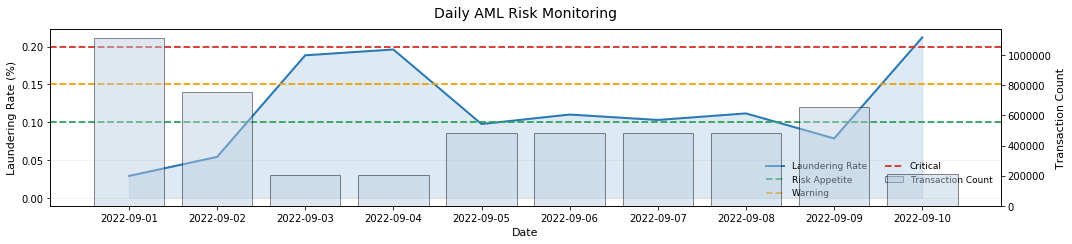

In [29]:
# Convert plotting data to NumPy arrays.
dates = daily_risk.index.to_numpy()
rates = daily_risk["laundering_rate"].to_numpy() * 100
counts = daily_risk["transaction_count"].to_numpy()

fig, ax = plt.subplots(figsize=(15, 3.5))
ax2 = ax.twinx()

# Plot daily laundering rate.
ax.plot(dates, rates, color="#2878B5", linewidth=2,
        label="Laundering Rate")
ax.fill_between(dates, rates, alpha=0.15, color="#2878B5")

# Plot daily transaction count on secondary axis.
ax2.bar(dates, counts, width=0.8, color="#B8CBE0",
        alpha=0.45, label="Transaction Count", edgecolor="black")

# Add risk thresholds.
ax.axhline(risk_appetite * 100, color="#2CA25F",
           linestyle="--", linewidth=1.8, label="Risk Appetite")
ax.axhline(warning_threshold * 100, color="#F0A202",
           linestyle="--", linewidth=1.8, label="Warning")
ax.axhline(critical_threshold * 100, color="#D73027",
           linestyle="--", linewidth=1.8, label="Critical")

ax.set_title("Daily AML Risk Monitoring", fontsize=14, pad=12)
ax.set_xlabel("Date", fontsize=11)
ax.set_ylabel("Laundering Rate (%)", fontsize=11)
ax2.set_ylabel("Transaction Count", fontsize=11)

# Combine legends from both axes.
lines, labels = ax.get_legend_handles_labels()
bars, bar_labels = ax2.get_legend_handles_labels()
ax.legend(lines + bars, labels + bar_labels,
          frameon=False, ncol=2, fontsize=9)

ax.tick_params(axis="both", labelsize=10)
ax2.tick_params(axis="y", labelsize=10)
ax.grid(axis="y", alpha=0.2)
#ax.spines["top"].set_visible(False)
#ax2.spines["top"].set_visible(False)

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [30]:
print("""
A careful observer will notice that the laundering rate spikes because the transaction count drops.
Care should be used when interpreting such results!
""")


A careful observer will notice that the laundering rate spikes because the transaction count drops.
Care should be used when interpreting such results!



# Quantifying uncertainty

In [31]:
from statsmodels.stats.proportion import proportion_confint

# Calculate daily laundering counts and transaction totals.
daily_risk = (
    model_df.set_index("Timestamp")["Is Laundering"]
    .resample("D")
    .agg(["sum", "count"])
    .rename(columns={
        "sum": "laundering_count",
        "count": "transaction_count"
    })
)

# Calculate daily laundering rate.
daily_risk["laundering_rate"] = (
    daily_risk["laundering_count"] /
    daily_risk["transaction_count"]
)

# Calculate 95% Wilson confidence intervals.
ci_low, ci_high = proportion_confint(
    count=daily_risk["laundering_count"],
    nobs=daily_risk["transaction_count"],
    alpha=0.05,
    method="wilson" # Wilson intervals are particularly useful for proportions, including rare events.
)

# The Wilson method calculates a confidence interval around a proportion, 
# such as our daily laundering rate. 
# It accounts for sample size and performs well when events are rare 
# or sample sizes are small. 
# The result is a lower and upper bound that shows how uncertain our observed rate is.

daily_risk["ci_lower"] = ci_low
daily_risk["ci_upper"] = ci_high

# Display results as percentages.
display(daily_risk.style.format({
    "laundering_rate": "{:.3%}",
    "ci_lower": "{:.3%}",
    "ci_upper": "{:.3%}"
}))

,laundering_count,transaction_count,laundering_rate,ci_lower,ci_upper
Timestamp,,,,,
2022-09-01 00:00:00,322,1114921,0.029%,0.026%,0.032%
2022-09-02 00:00:00,408,754449,0.054%,0.049%,0.060%
2022-09-03 00:00:00,391,207382,0.189%,0.171%,0.208%
2022-09-04 00:00:00,407,207430,0.196%,0.178%,0.216%
2022-09-05 00:00:00,471,482650,0.098%,0.089%,0.107%
2022-09-06 00:00:00,531,482089,0.110%,0.101%,0.120%
2022-09-07 00:00:00,497,482751,0.103%,0.094%,0.112%
2022-09-08 00:00:00,539,482773,0.112%,0.103%,0.121%
2022-09-09 00:00:00,514,654467,0.079%,0.072%,0.086%


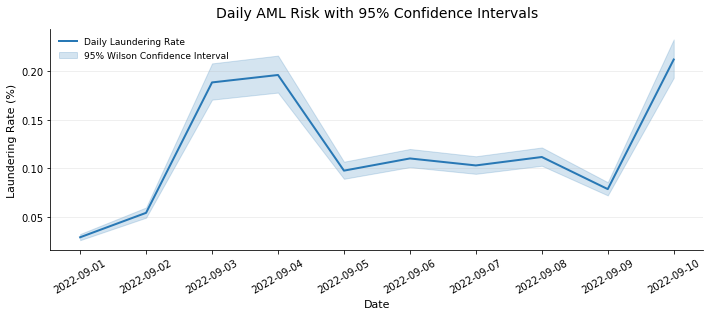

In [32]:
# Convert plotting data to NumPy arrays.
dates = daily_risk.index.to_numpy()
rates = daily_risk["laundering_rate"].to_numpy() * 100
lower = daily_risk["ci_lower"].to_numpy() * 100
upper = daily_risk["ci_upper"].to_numpy() * 100

fig, ax = plt.subplots(figsize=(10, 4.5))

# Plot observed laundering rate and confidence interval.
ax.plot(
    dates, rates,
    color="#2878B5",
    linewidth=2,
    label="Daily Laundering Rate"
)

ax.fill_between(
    dates, lower, upper,
    color="#2878B5",
    alpha=0.20,
    label="95% Wilson Confidence Interval"
)

ax.set_title("Daily AML Risk with 95% Confidence Intervals",
             fontsize=14, pad=12)
ax.set_xlabel("Date", fontsize=11)
ax.set_ylabel("Laundering Rate (%)", fontsize=11)

ax.tick_params(axis="both", labelsize=10)
ax.legend(frameon=False, fontsize=9)
ax.grid(axis="y", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [33]:
print("""
So interesting...
The uncertainty increases where the transaction counts dip and the laundering rate increases.

Confidence intervals use the sample size, so it makes sense that, as the transaction count/sample size decreases,
the uncertainty increases.
""")


So interesting...
The uncertainty increases where the transaction counts dip and the laundering rate increases.

Confidence intervals use the sample size, so it makes sense that, as the transaction count/sample size decreases,
the uncertainty increases.



In [34]:
print("done")

done
